# MEMC exercise 4 – Continuous distributions

---

In exercise 3 we built discrete variables out of a single uniform number $\gamma$. Here we do the
same for **continuous distributions**. The key is a single theorem:

> **The inverse transform.** If a variable $X$ has a continuous, strictly increasing distribution
> function $F$ and $\gamma \sim R(0, 1)$, then $X = F^{-1}(\gamma)$ has the distribution function $F$.

In this notebook you see:

- why the theorem holds and how to **proceed step by step** by it
- generators: uniform, exponential, **Cauchy**, triangular, piecewise constant density
- why the **law of large numbers fails** for the Cauchy distribution (and what that changes from the
  point of view of notebook 0)
- what to do when $F^{-1}$ has no closed form (the normal distribution)

In [1]:
import math
import random
import time
from bisect import bisect_right
from itertools import accumulate

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def samples(sampler, n):
    '''n calls of the generator -> list of samples. This is the output of the whole method.'''
    return [sampler() for _ in range(n)]


def estimate(xs):
    '''Monte Carlo from a finished list: the average and its standard error sigma/sqrt(n).'''
    n = len(xs)
    mean = sum(xs) / n
    var = sum((x - mean) ** 2 for x in xs) / (n - 1)
    return mean, math.sqrt(var / n)


def check(name, mean, se, exact, k=5):
    '''Prints the estimate and verifies it lies within k standard errors of the exact value.'''
    print(f"{name}: {mean:.5f} +- {se:.5f}  (exact {exact:.5f})")
    assert abs(mean - exact) <= k * se, name


def hist_density(ax, xs, span, pdf, name, bins=60):
    '''A histogram of the samples (scaled to density height) with the exact density in red.'''
    w = (span[1] - span[0]) / bins
    ax.hist(xs, bins=bins, range=span, weights=[1 / (len(xs) * w)] * len(xs), alpha=0.6)
    grid = [span[0] + (span[1] - span[0]) * i / 400 for i in range(401)]
    ax.plot(grid, [pdf(x) for x in grid], "r")
    ax.set_title(name)

## 1. The inverse transform

### Why it works

The distribution function $F$ is increasing, so $F^{-1}$ exists, and for any $x$

$$P\big(F^{-1}(\gamma) \le x\big) = P\big(\gamma \le F(x)\big) = F(x),$$

because $\gamma$ is uniform on $[0, 1]$ and $P(\gamma \le t) = t$. So the variable $F^{-1}(\gamma)$
has exactly the distribution function $F$.

### The procedure

1. Write down the distribution function $F(x) = \int_{-\infty}^x f(t)\,dt$.
2. Solve the equation $F(x) = \gamma$ for $x$ (this gives $x = F^{-1}(\gamma)$).
3. Substitute $\gamma = $ `random.random()` into $F^{-1}$.

It is the same idea as in the discrete case: there we looked for the smallest $k$ with
$\gamma < F(k)$, here we solve $F(x) = \gamma$ exactly.

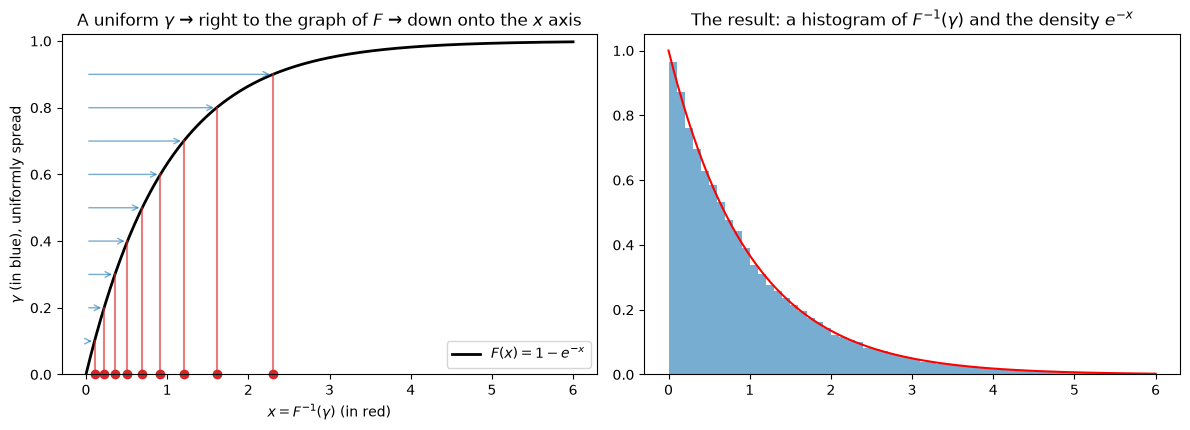

In [2]:
# how the inverse transform works, on the example of Exp(1): F(x) = 1 - exp(-x)
F_ = lambda x: 1 - math.exp(-x)
Finv_ = lambda gamma: -math.log(1 - gamma)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

ax = axes[0]
xx = [i / 50 for i in range(0, 301)]
ax.plot(xx, [F_(x) for x in xx], "k", lw=2, label="$F(x) = 1 - e^{-x}$")
us = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
for u in us:
    x = Finv_(u)
    ax.annotate("", xy=(x, u), xytext=(0, u), arrowprops=dict(arrowstyle="->", color="tab:blue", alpha=0.6))
    ax.plot([x, x], [0, u], color="tab:red", alpha=0.6)
    ax.plot([x], [0], "o", color="tab:red", clip_on=False)
ax.set_xlabel("$x = F^{-1}(\\gamma)$ (in red)")
ax.set_ylabel("$\\gamma$ (in blue), uniformly spread")
ax.set_ylim(0, 1.02)
ax.set_title("A uniform $\\gamma$ → right to the graph of $F$ → down onto the $x$ axis")
ax.legend(loc="lower right")

xs_ = [Finv_(1 - random.random()) for _ in range(100_000)]
hist_density(axes[1], xs_, (0, 6), lambda x: math.exp(-x), "The result: a histogram of $F^{-1}(\\gamma)$ and the density $e^{-x}$")
plt.tight_layout()
plt.show()

The steep part of $F$ (where the density is large) **compresses** the uniformly spread values of
$\gamma$ onto a small stretch of the $x$ axis, and the flat part spreads them out instead. That is
exactly what turns a uniform distribution into one with density $f = F'$.

### An overview of the distributions in this notebook

**Uniform** $R(a,b)$:

$$F(x) = \frac{x - a}{b - a} \qquad\Longrightarrow\qquad F^{-1}(\gamma) = a + (b - a)\,\gamma$$

**Exponential** $\operatorname{Exp}(\lambda)$:

$$F(x) = 1 - e^{-\lambda x} \qquad\Longrightarrow\qquad F^{-1}(\gamma) = -\frac{\ln(1 - \gamma)}{\lambda}$$

**Cauchy** $C(x_0, s)$:

$$F(x) = \frac{1}{2} + \frac{1}{\pi}\arctan\frac{x - x_0}{s} \qquad\Longrightarrow\qquad F^{-1}(\gamma) = x_0 + s\,\tan\Big(\pi\big(\gamma - \tfrac{1}{2}\big)\Big)$$

**The density $2x$ on $[0, 1]$** (the claim size from exercise 2; in **exercise 9** we finish the
insurance company off with it):

$$F(x) = x^2 \qquad\Longrightarrow\qquad F^{-1}(\gamma) = \sqrt{\gamma}$$

## 2. The uniform and exponential distributions

For the exponential distribution it pays to notice that $1 - \gamma$ is uniform too. So instead of
$-\ln(1 - \gamma)$ we could also write $-\ln \gamma$ — but careful: `random.random()` returns a
number from $[0, 1)$, so $\ln \gamma$ would fail for $\gamma = 0$. The value $1 - \gamma$ lies in
$(0, 1]$ and the logarithm is always defined.

In [3]:
def uniform(a, b):
    # F(x) = (x - a)/(b - a)  =>  F^-1(gamma) = a + (b - a)*gamma
    return a + (b - a) * random.random()


def exponential(lam):
    # F(x) = 1 - e^(-lam*x)  =>  F^-1(gamma) = -ln(1 - gamma)/lam
    # 1 - gamma is uniform too, and for random() from [0, 1) it is never 0
    return -math.log(1.0 - random.random()) / lam


n = 200_000

xs = samples(lambda: uniform(2, 5), n)
check("uniform(2, 5): E X", *estimate(xs), 3.5)

xs = samples(lambda: exponential(2.0), n)
check("exponential(2): E X", *estimate(xs), 0.5)

uniform(2, 5): E X: 3.50049 +- 0.00194  (exact 3.50000)
exponential(2): E X: 0.49958 +- 0.00112  (exact 0.50000)


## 3. The Cauchy distribution: when the law of large numbers fails

The Cauchy distribution has the density
$f(x) = \dfrac{1}{\pi s\,\big(1 + ((x - x_0)/s)^2\big)}$. It looks like a bell, but with **heavy
tails**: large values are so frequent that **the expectation does not exist** (the integral
$\int |x| f(x)\,dx$ diverges), and so a fortiori neither does the variance.

The consequence: nothing we learned in notebook 0 applies here. The law of large numbers,
Chebyshev's inequality and the CLT all assume a finite expectation and variance.

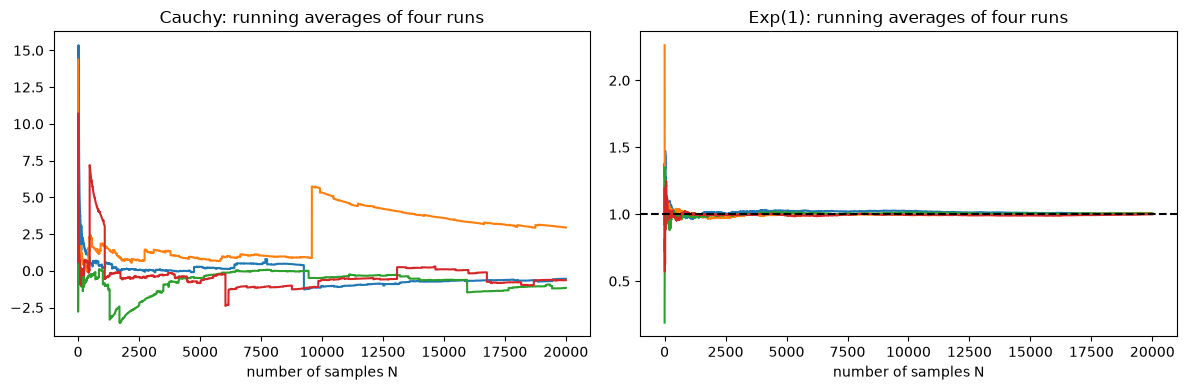

In [4]:
def cauchy(x0=0.0, s=1.0):
    # F(x) = 1/2 + atan((x - x0)/s)/pi  =>  F^-1(gamma) = x0 + s*tan(pi*(gamma - 1/2))
    return x0 + s * math.tan(math.pi * (random.random() - 0.5))


def running_averages(sampler, n):
    s = 0.0
    out = []
    for i in range(1, n + 1):
        s += sampler()
        out.append(s / i)
    return out


fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for _ in range(4):
    axes[0].plot(running_averages(cauchy, 20_000))
    axes[1].plot(running_averages(lambda: exponential(1.0), 20_000))
axes[0].set_title("Cauchy: running averages of four runs")
axes[1].set_title("Exp(1): running averages of four runs")
axes[1].axhline(1.0, color="black", linestyle="--")
for ax in axes:
    ax.set_xlabel("number of samples N")
plt.tight_layout()
plt.show()

**Careful, a single run is deceptive.** The Cauchy curves may come to look "calm" after a while:
every new sample $x$ changes the average by only $x/N$, so the motion slows down. But whenever an
extreme value arrives, the average jumps again (you can see it in one of the runs), and **where the
average settles is different in every run**. For the exponential distribution all the runs pull
towards the same value $1$.

So what decides the matter is how the averages are **spread across many runs**. For every $N$ we take
300 independent runs and show the lower and upper quartile (half the runs lie between them) of the
deviation of the average from the centre:

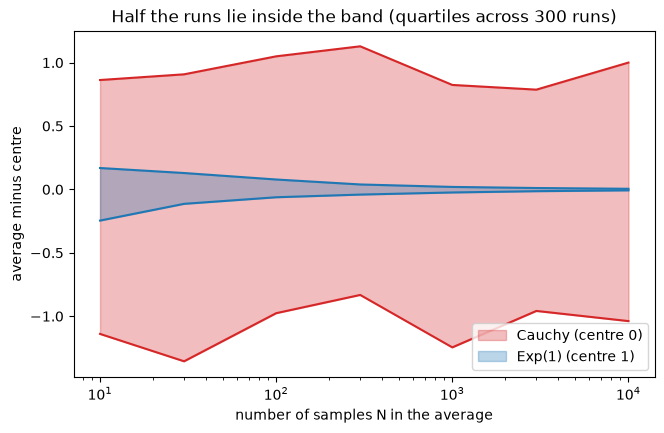

In [5]:
checkpoints = [10, 30, 100, 300, 1_000, 3_000, 10_000]
checkpoint_set = set(checkpoints)


def average_quartiles(sampler, center, runs=300):
    '''For every N in checkpoints: the lower and upper quartile of (average of N samples - center) across runs.'''
    values = {N: [] for N in checkpoints}
    for _ in range(runs):
        s = 0.0
        for i in range(1, checkpoints[-1] + 1):
            s += sampler()
            if i in checkpoint_set:
                values[i].append(s / i - center)
    lower, upper = [], []
    for N in checkpoints:
        h = sorted(values[N])
        lower.append(h[len(h) // 4])
        upper.append(h[3 * len(h) // 4])
    return lower, upper


plt.figure(figsize=(7.5, 4.5))
for name, sampler, center, color in (("Cauchy (centre 0)", cauchy, 0.0, "tab:red"),
                                     ("Exp(1) (centre 1)", lambda: exponential(1.0), 1.0, "tab:blue")):
    lower, upper = average_quartiles(sampler, center)
    plt.fill_between(checkpoints, lower, upper, alpha=0.3, color=color, label=name)
    plt.plot(checkpoints, lower, color=color)
    plt.plot(checkpoints, upper, color=color)
plt.xscale("log")
plt.xlabel("number of samples N in the average")
plt.ylabel("average minus centre")
plt.title("Half the runs lie inside the band (quartiles across 300 runs)")
plt.legend()
plt.show()

For the exponential distribution the band narrows like $1/\sqrt{N}$, so the averages do converge as
$N$ grows. For the Cauchy it stays **just as wide**, with the quartiles sitting (up to the noise from
300 runs) at $\pm 1$: those are the quartiles of the Cauchy distribution itself, because
$P(|X| < 1) = \tfrac12$. The average of $N$ independent Cauchy variables has **exactly the same
Cauchy distribution again**, however large $N$ is. Averaging does not help here at all.

### What **can** be estimated

The expectation does not exist, but probabilities always do. From those same samples we can estimate,
say, $P(|X| < 1) = \tfrac12$ (an average of indicators is a Bernoulli variable with finite
variance):

In [6]:
xs = samples(cauchy, n)
hits = [float(abs(x) < 1) for x in xs]
check("P(|Cauchy| < 1)", *estimate(hits), 0.5)

# the average of 100 Cauchy variables has the same distribution as a single one:
averages = [sum(cauchy() for _ in range(100)) / 100 for _ in range(5_000)]
check("P(|average of 100| < 1)", *estimate([float(abs(m) < 1) for m in averages]), 0.5)

P(|Cauchy| < 1): 0.49785 +- 0.00112  (exact 0.50000)
P(|average of 100| < 1): 0.49820 +- 0.00707  (exact 0.50000)


The second line shows the essential point: the probability that $|\text{average}| < 1$ is $0.5$ for
$N = 1$ just as it is for $N = 100$. For a distribution with finite variance the averages would pull
towards $\mu$ as $N$ grows and this probability would rise towards $1$.

## 4. The triangular distribution: $F$ in pieces

The density grows linearly on $[a, c]$ and falls linearly on $[c, b]$. The distribution function is
**piecewise** quadratic, and so the inverse function has two formulas as well. We use the value
$F(c) = \dfrac{c - a}{b - a}$ as the threshold to compare $\gamma$ against:

$$F(x) = \begin{cases}
\dfrac{(x-a)^2}{(b-a)(c-a)}, & a \le x \le c,\\[2mm]
1 - \dfrac{(b-x)^2}{(b-a)(b-c)}, & c < x \le b,
\end{cases}
\qquad
F^{-1}(\gamma) = \begin{cases}
a + \sqrt{\gamma\,(b-a)(c-a)}, & \gamma < F(c),\\[1mm]
b - \sqrt{(1-\gamma)(b-a)(b-c)}, & \gamma \ge F(c).
\end{cases}$$

In [7]:
def triangular(a, b, c):
    '''The density grows on [a, c] and falls on [c, b]. The inverse function is defined piecewise.'''
    gamma = random.random()
    threshold = (c - a) / (b - a)   # F(c)
    if gamma < threshold:
        return a + math.sqrt(gamma * (b - a) * (c - a))
    return b - math.sqrt((1.0 - gamma) * (b - a) * (b - c))


xs = samples(lambda: triangular(0, 4, 1), n)
check("triangular(0, 4, 1): E X", *estimate(xs), (0 + 4 + 1) / 3)

triangular(0, 4, 1): E X: 1.66795 +- 0.00189  (exact 1.66667)


## 5. A piecewise constant density

The density is constant on the segments $[e_i, e_{i+1})$ with heights $h_i$ (a staircase density).
The distribution function is piecewise linear, so its inverse has no single formula. Fortunately the
problem **splits into two easy ones**:

1. **Which segment?** This is a discrete problem: segment $i$ has a probability equal to its area
   $p_i = \dfrac{(e_{i+1} - e_i)\,h_i}{\sum_j (e_{j+1} - e_j)\,h_j}$ (the basic algorithm from
   exercise 3).
2. **Where inside the segment?** Inside a segment the density is constant, so we use the uniform
   distribution.

The heights $h_i$ do not have to be normalized; the division by the sum takes care of the
normalization. We start with five segments:

In [8]:
def piecewise_const(edges, heights):
    '''A piecewise constant density.

    edges   = [e_0, e_1, ..., e_n]   the segment boundaries, one more than there are heights
    heights = [h_0, ..., h_(n-1)]    the height on the segment [e_i, e_(i+1)); need not be normalized
    '''
    n_seg = len(heights)

    # the area of each segment = width * height; divided by the sum it is the probability p_i
    areas = [(edges[i + 1] - edges[i]) * heights[i] for i in range(n_seg)]
    total = sum(areas)

    # step 1: subtract p_i until you drop below zero (the basic algorithm from the discrete case)
    gamma = random.random()
    for i in range(n_seg):
        gamma -= areas[i] / total
        if gamma < 0:
            break
    # once the loop ends, i holds the index of the chosen segment
    # (if rounding left gamma >= 0, i stays at n_seg - 1, which is the right fallback)

    # step 2: inside the segment the density is constant
    return uniform(edges[i], edges[i + 1])


def step_mean(edges, heights):
    '''The exact expectation of a staircase density: the sum of (segment probability) * (segment midpoint).'''
    areas = [(edges[i + 1] - edges[i]) * heights[i] for i in range(len(heights))]
    centers = [(edges[i] + edges[i + 1]) / 2 for i in range(len(heights))]
    return sum(o * s for o, s in zip(areas, centers)) / sum(areas)


# five segments of width 1, unnormalized heights
ed5 = [0, 1, 2, 3, 4, 5]
ht5 = [1, 3, 2, 0.5, 1.5]

xs = samples(lambda: piecewise_const(ed5, ht5), n)
check("piecewise (5 segments): E X", *estimate(xs), step_mean(ed5, ht5))

piecewise (5 segments): E X: 2.31513 +- 0.00295  (exact 2.31250)


### Steps approximate any curve

The real strength of this method lies elsewhere: **every density $f$ can be replaced by a staircase
one**. We cut the interval $[a, b]$ into $n$ small segments of width $\Delta x$ and on each one we
replace $f$ by a constant (the value at the middle of the segment, say). The area of the column
$f(x_i)\,\Delta x$ is approximately the probability that the value falls into segment $i$. The finer
the division, the better the approximation — and since the heights need not be normalized, we do not
even have to compute the normalizing constant.

Let us try it on a "random" curve with two humps, for which $F^{-1}$ has no nice formula:

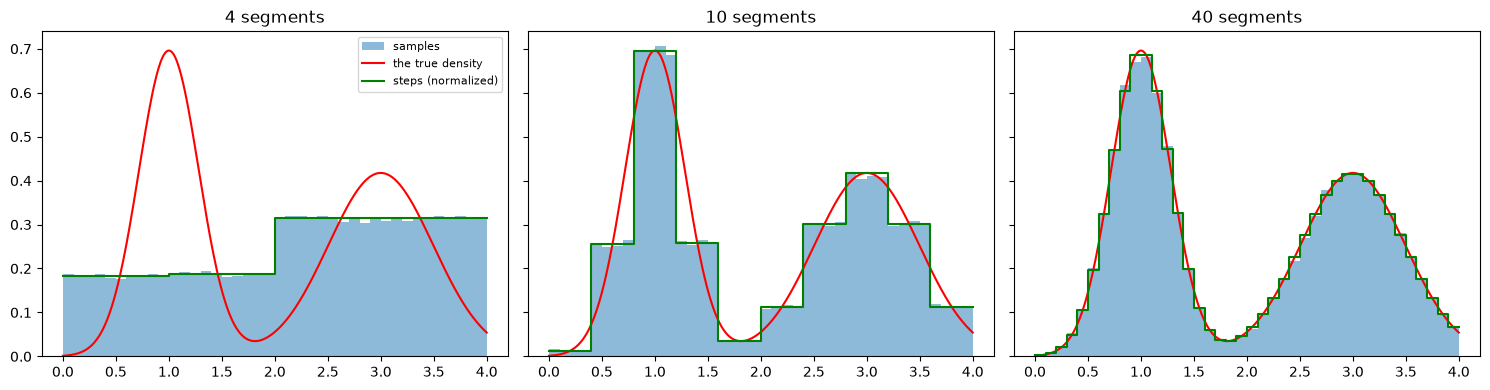

In [9]:
def curve(x):
    '''An arbitrary (unnormalized) density on [0, 4]: two humps.'''
    return math.exp(-((x - 1) / 0.4) ** 2) + 0.6 * math.exp(-((x - 3) / 0.7) ** 2)


def step_density(f, a, b, n_seg):
    '''Cuts [a, b] into n_seg segments; the height = the value of f at the middle of the segment.'''
    dx = (b - a) / n_seg
    edges = [a + i * dx for i in range(n_seg + 1)]
    heights = [f(a + (i + 0.5) * dx) for i in range(n_seg)]
    return edges, heights


def make_bisect(p):
    '''A discrete distribution with probabilities p: cumulative sums + bisection (exercise 3).'''
    cum = list(accumulate(p))
    return lambda: min(bisect_right(cum, random.random()), len(p) - 1)


def make_piecewise_const(edges, heights):
    '''The same as piecewise_const, but the segment is found by bisection: O(log n) instead of O(n) per draw.'''
    areas = [(edges[i + 1] - edges[i]) * heights[i] for i in range(len(heights))]
    total = sum(areas)
    pick = make_bisect([o / total for o in areas])

    def sample():
        i = pick()
        return uniform(edges[i], edges[i + 1])

    return sample


# the "exact" value: very fine steps (100 000 segments) are taken as the truth
ed_ref, ht_ref = step_density(curve, 0, 4, 100_000)
E_exact = step_mean(ed_ref, ht_ref)
Z = sum(ht_ref) * (4 / 100_000)   # the area under the curve (the normalizing constant)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
grid = [4 * i / 400 for i in range(401)]
for ax, n_seg in zip(axes, (4, 10, 40)):
    ed, ht = step_density(curve, 0, 4, n_seg)
    sampler = make_piecewise_const(ed, ht)
    xs = samples(sampler, 100_000)
    w = 4 / 40
    ax.hist(xs, bins=40, range=(0, 4), weights=[1 / (len(xs) * w)] * len(xs), alpha=0.5, label="samples")
    ax.plot(grid, [curve(x) / Z for x in grid], "r", label="the true density")
    A = sum(ht) * (4 / n_seg)   # the area of the steps (differs from Z; the sampler normalizes by it)
    ax.step(ed, [v / A for v in ht] + [ht[-1] / A], where="post", color="green", label="steps (normalized)")
    ax.set_title(f"{n_seg} segments")
axes[0].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

Even with four segments you can see what is going on, and with forty the steps are almost
indistinguishable from the curve. How fast does the approximation improve? The expectation of a
staircase density can be computed **exactly** from the formula above, so we see the approximation
error without the noise of the simulation:

In [10]:
print(f"the exact expectation of the curve: {E_exact:.6f}\n")
print(f"{'segments':>8s} {'E X (steps)':>14s} {'error':>12s}")
previous = None
for n_seg in (2, 4, 8, 16, 32, 64, 128):
    ed, ht = step_density(curve, 0, 4, n_seg)
    E = step_mean(ed, ht)
    err = abs(E - E_exact)
    ratio = f"   (previous error / this one = {previous / err:.1f})" if previous else ""
    print(f"{n_seg:8d} {E:14.6f} {err:12.2e}{ratio}")
    previous = err

# and a simulation from the 64-segment steps matches their exact expectation
ed, ht = step_density(curve, 0, 4, 64)
check("simulation from 64 steps: E X", *estimate(samples(make_piecewise_const(ed, ht), n)), step_mean(ed, ht))

the exact expectation of the curve: 2.000357

segments    E X (steps)        error
       2       1.749920     2.50e-01
       4       2.260250     2.60e-01   (previous error / this one = 1.0)
       8       2.005998     5.64e-03   (previous error / this one = 46.1)
      16       2.001299     9.42e-04   (previous error / this one = 6.0)
      32       2.000590     2.33e-04   (previous error / this one = 4.0)
      64       2.000415     5.80e-05   (previous error / this one = 4.0)
     128       2.000371     1.45e-05   (previous error / this one = 4.0)
simulation from 64 steps: E X: 2.00272 +- 0.00237  (exact 2.00041)


For a coarse division (up to eight segments) the error behaves irregularly, because the segments are
wider than the humps of the curve. But once the segments are narrow enough, **doubling the number of
segments quarters the error exactly** (the ratio $4.0$ in the table): this is a second-order
approximation, just like the rectangle (midpoint) rule in quadrature. For large $n$ it pays to find
the segment by bisection (`make_piecewise_const`): that costs $O(\log n)$ instead of $O(n)$ per draw.

> **A note:** the staircase density is a **different** density from the original one. We have not
> removed the approximation, we have only traded it for an error we can control through the number of
> segments. If we want samples from exactly the original density, we use the rejection method
> (exercise 6).

## 6. All the distributions at once

As a check we compare the histograms from our generators against the exact densities.

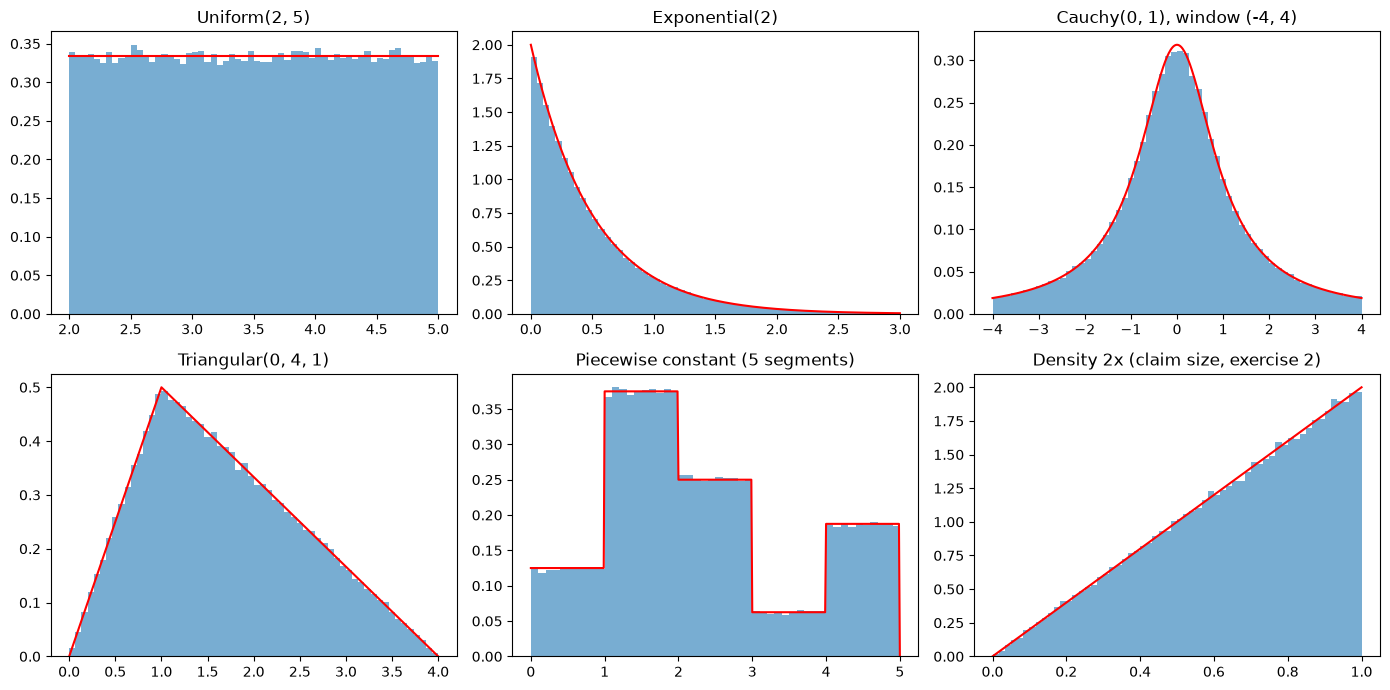

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

xs = samples(lambda: uniform(2, 5), n)
hist_density(axes[0][0], xs, (2, 5), lambda x: 1 / 3, "Uniform(2, 5)")

xs = samples(lambda: exponential(2.0), n)
hist_density(axes[0][1], xs, (0, 3), lambda x: 2 * math.exp(-2 * x), "Exponential(2)")

xs = samples(cauchy, n)
hist_density(axes[0][2], xs, (-4, 4), lambda x: 1 / (math.pi * (1 + x * x)), "Cauchy(0, 1), window (-4, 4)")


def tri_pdf(a, b, c):
    def f(x):
        if x < a or x > b:
            return 0.0
        if x <= c:
            return 2 * (x - a) / ((b - a) * (c - a))
        return 2 * (b - x) / ((b - a) * (b - c))
    return f


xs = samples(lambda: triangular(0, 4, 1), n)
hist_density(axes[1][0], xs, (0, 4), tri_pdf(0, 4, 1), "Triangular(0, 4, 1)")

xs = samples(lambda: piecewise_const(ed5, ht5), n)


def step_pdf(edges, heights):
    total = sum((edges[i + 1] - edges[i]) * heights[i] for i in range(len(heights)))

    def f(x):
        for i in range(len(heights)):
            if edges[i] <= x < edges[i + 1]:
                return heights[i] / total
        return 0.0
    return f


hist_density(axes[1][1], xs, (0, 5), step_pdf(ed5, ht5), "Piecewise constant (5 segments)", bins=50)

xs = samples(lambda: math.sqrt(random.random()), n)
hist_density(axes[1][2], xs, (0, 1), lambda x: 2 * x, "Density 2x (claim size, exercise 2)")

plt.tight_layout()
plt.show()

The histograms (in blue) trace the densities (in red). For the Cauchy distribution we only draw the
window $(-4, 4)$, because the tails reach out to infinity.

## 7. When $F^{-1}$ has no formula: numerical inversion

The normal distribution has $F(x) = \Phi(x)$, which we can compute (via the error function `erf`),
but the equation $\Phi(x) = \gamma$ cannot be solved in closed form. The solution: **solve it
numerically by bisection**, since $F$ is increasing. The procedure is general and works for any
continuous increasing $F$.

The cost, however, is high: every draw means dozens of evaluations of $F$. Better methods for the
normal distribution (the rejection method) are in exercise 6.

In [12]:
def Phi(x):
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))


def invert_by_bisection(F, gamma, lo=-10.0, hi=10.0, iterations=60):
    '''Solves F(x) = gamma by bisecting the interval [lo, hi]; F must be increasing.'''
    for _ in range(iterations):
        mid = (lo + hi) / 2
        if F(mid) < gamma:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2


m_norm = 50_000
t0 = time.perf_counter()
xs = samples(lambda: invert_by_bisection(Phi, random.random()), m_norm)
t = (time.perf_counter() - t0) / m_norm

check("N(0,1): E X", *estimate(xs), 0.0)
check("N(0,1): E X^2", *estimate([x * x for x in xs]), 1.0)
print(f"time per draw: {t * 1e6:.0f} microseconds (60 evaluations of F)")

N(0,1): E X: -0.00066 +- 0.00447  (exact 0.00000)
N(0,1): E X^2: 0.99818 +- 0.00627  (exact 1.00000)
time per draw: 13 microseconds (60 evaluations of F)


## 8. An alternative: NumPy

NumPy has all of these distributions ready-made. Watch out for the **parametrization**:
`exponential` takes `scale` $= 1/\lambda$ (not $\lambda$), and `triangular` takes
`left, mode, right`.

In [13]:
try:
    import numpy as np

    rng = np.random.default_rng(1)
    N = 1_000_000

    t0 = time.perf_counter()
    u = rng.uniform(2, 5, size=N)
    e = rng.exponential(1 / 2.0, size=N)            # scale = 1/lambda
    c = rng.standard_cauchy(size=N)
    tr = rng.triangular(0, 1, 4, size=N)             # left, mode, right (a different order from ours!)
    t = time.perf_counter() - t0

    print(f"E uniform(2,5) = {u.mean():.4f}  (3.5)")
    print(f"E exponential(2) = {e.mean():.4f}  (0.5)")
    print(f"P(|Cauchy| < 1) = {(np.abs(c) < 1).mean():.4f}  (0.5)")
    print(f"E triangular(0,4,1) = {tr.mean():.4f}  ({5 / 3:.4f})")
    print(f"{4 * N:,} samples in {t:.2f} s".replace(",", " "))

    # the inverse transform, vectorized: a whole array at once
    gamma = rng.random(N)
    print(f"inverse transform, exponential: {(-np.log(1 - gamma) / 2.0).mean():.4f}  (0.5)")
except ModuleNotFoundError:
    print("NumPy is not installed, run:  uv sync")

E uniform(2,5) = 3.4999  (3.5)
E exponential(2) = 0.5006  (0.5)
P(|Cauchy| < 1) = 0.4998  (0.5)
E triangular(0,4,1) = 1.6667  (1.6667)
4 000 000 samples in 0.04 s
inverse transform, exponential: 0.4998  (0.5)


Notice the order of the parameters of `triangular`: NumPy takes `(left, mode, right)`, our generator
takes `(a, b, c)` with the peak $c$ **last**. When transcribing code between libraries this is a
common trap.

## Summary

| Concept | What to remember |
|---------|------------------|
| The inverse transform | $X = F^{-1}(\gamma)$ has the distribution function $F$; it is enough to solve $F(x) = \gamma$ |
| Exponential | $-\ln(1 - \gamma)/\lambda$; we use $1 - \gamma$ because `random()` can return $0$ |
| A piecewise $F$ | a piecewise inverse formula (triangular); we compare $\gamma$ against $F$ at the breakpoint |
| A piecewise constant density | two problems: the segment (discretely), then uniformly inside the segment; with enough segments it approximates any density (from a fine enough division the error falls like $1/n^2$) |
| Cauchy | has no expectation; neither the law of large numbers nor the CLT holds; probabilities can still be estimated |
| $F^{-1}$ without a formula | numerical inversion by bisection — general, but slow |
| Testing | the expectation, possibly $E X^2$ or a probability; the histogram against the density |

### Try it yourself

1. **The Pareto distribution** with $F(x) = 1 - x^{-\alpha}$ for $x \ge 1$: derive $F^{-1}$, write the
   generator and verify $E X = \dfrac{\alpha}{\alpha - 1}$ for $\alpha = 3$ (for $\alpha \le 1$ the
   expectation does not exist; what happens to the estimate then?).
2. **The Laplace distribution** (the double exponential) with density $f(x) = \tfrac12 e^{-|x|}$: $F$
   is defined piecewise. Derive $F^{-1}$ and verify $E X = 0$, $E X^2 = 2$.
3. The distribution of **the maximum of two uniforms** $\max(\gamma_1, \gamma_2)$ has $F(x) = x^2$.
   Show that this is the same distribution as $\sqrt{\gamma}$, and verify it by simulation in both
   ways.